# KMA/MSM – Přednáška 5a: Odlehlá pozorování v jednorozměrných datech

**Blanka Šedivá, KMA FAV ZČU Plzeň**

Notebook doprovází první část přednášky P05. Vícerozměrné metody (Mahalanobis, MCD, LOF, Isolation Forest, …)
jsou v navazujícím notebooku *P05b*.

> Odlehlé pozorování je hodnota, která se od ostatních odlišuje natolik, že vzbuzuje podezření, že byla
> generována jiným mechanismem (Hawkins, 1980).

## Obsah

1. Data pro ukázky
2. Parametrické metody (předpoklad normality): Z-skóre a pravidlo 3σ, Chauvenetovo kritérium, Grubbsův test, Dixonův test, GESD (Rosnerův test)
3. Maskování – proč jedno odlehlé pozorování „schová“ druhé
4. Robustní a neparametrické metody: modifikované Z-skóre (MAD), Tukeyho pravidlo (boxplot)
5. Srovnání metod na simulovaných a reálných datech (Iris)
6. Robustní odhady polohy
7. Co s odlehlými hodnotami dělat
8. Úlohy

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.datasets import load_iris

RNG = np.random.default_rng(2026)   # sdileny generator -> reprodukovatelnost
plt.rcParams.update({
    'figure.figsize': (11, 4), 'figure.dpi': 110, 'font.size': 11,
    'axes.grid': True, 'grid.alpha': 0.3,
    'axes.spines.top': False, 'axes.spines.right': False,
})
C_IN, C_OUT = '#4C72B0', '#C44E52'  # modra = bezne, cervena = odlehle


def strip(ax, x, flags, title=''):
    # jednorozmerny bodovy graf s vyznacenymi odlehlymi hodnotami
    f = np.asarray(flags, bool)
    y = RNG.uniform(-0.15, 0.15, len(x))       # mirny rozptyl ve svislem smeru, at se body neprekryvaji
    ax.scatter(x[~f], y[~f], s=25, c=C_IN, alpha=.7, edgecolor='none')
    ax.scatter(x[f], y[f], s=70, c=C_OUT, marker='X', label='odlehlé (n={})'.format(int(f.sum())))
    ax.set_yticks([]); ax.set_ylim(-0.6, 0.6)
    ax.set_title(title); ax.legend(loc='upper left', fontsize=9)
    return ax

---
# 1. Data pro ukázky

* **Simulovaná data:** 40 hodnot z $N(10, 1)$ a k nim dvě podezřelé hodnoty 14,2 a 14,6.
  Víme tedy, která pozorování jsou „pravá“ odlehlá.
* **Reálná data:** šířka kališního lístku (*sepal width*) z datové sady Iris – na boxplotu
  je u ní vidět několik bodů za „vousy“.

simulovaná data: n = 42, průměr = 10.26, s = 1.24
Iris sepal width: n = 150, průměr = 3.06, s = 0.44


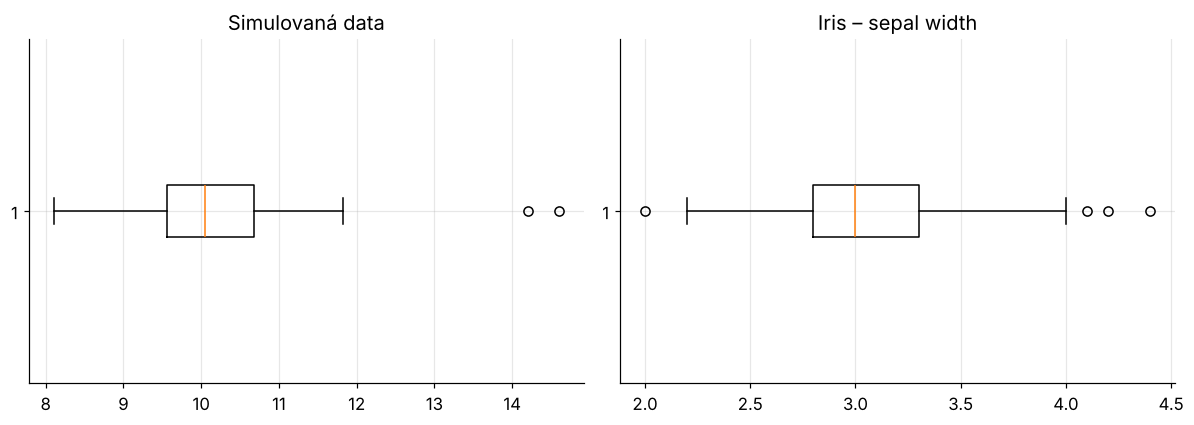

In [2]:
x_sim = np.r_[RNG.normal(10, 1, 40), 14.2, 14.6]
true_out = np.r_[np.zeros(40, bool), True, True]

iris = load_iris(as_frame=True)
x_iris = iris.data['sepal width (cm)'].to_numpy()

print('simulovaná data: n = {}, průměr = {:.2f}, s = {:.2f}'.format(len(x_sim), x_sim.mean(), x_sim.std(ddof=1)))
print('Iris sepal width: n = {}, průměr = {:.2f}, s = {:.2f}'.format(len(x_iris), x_iris.mean(), x_iris.std(ddof=1)))

fig, axes = plt.subplots(1, 2)
axes[0].boxplot(x_sim, orientation='horizontal'); axes[0].set_title('Simulovaná data')
axes[1].boxplot(x_iris, orientation='horizontal'); axes[1].set_title('Iris – sepal width')
plt.tight_layout(); plt.show()

---
# 2. Parametrické metody (předpoklad normality)

## 2.1 Z-skóre a pravidlo 3σ

$$z_i=\frac{x_i-\bar x}{s},$$
za odlehlé považujeme $|z_i|>3$. Pro normální data je $P(|Z|>3)\doteq 0{,}0027$, takže
**i bez odlehlých hodnot** očekáváme při $n=1000$ asi 2–3 „falešné poplachy“.

In [3]:
def zscore_rule(x, c=3):
    z = (x - x.mean()) / x.std(ddof=1)
    return np.abs(z) > c, z

f_z, z = zscore_rule(x_sim)
print('Z-skóre podezřelých hodnot:', np.round(z[-2:], 2))
print('označeno:', np.where(f_z)[0])

# kolik falesnych poplachu da pravidlo 3 sigma na cistych normalnich datech?
for n in [20, 100, 1000, 10000]:
    fp = np.mean([zscore_rule(RNG.normal(size=n))[0].sum() for _ in range(300)])
    print('n = {:5d}: průměrně {:.2f} falešně označených (teorie {:.2f})'.format(n, fp, n * 2 * stats.norm.sf(3)))

Z-skóre podezřelých hodnot: [3.18 3.5 ]
označeno: [40 41]
n =    20: průměrně 0.01 falešně označených (teorie 0.05)
n =   100: průměrně 0.23 falešně označených (teorie 0.27)


n =  1000: průměrně 2.60 falešně označených (teorie 2.70)
n = 10000: průměrně 26.62 falešně označených (teorie 27.00)


## 2.2 Chauvenetovo kritérium

Hodnotu $x_i$ vyřadíme, pokud je **očekávaný počet** stejně nebo více odlehlých hodnot ve výběru rozsahu $n$ menší než 1/2:
$$n\cdot P(|Z|>|z_i|)<0{,}5 .$$
Mez se tak automaticky posouvá s rozsahem výběru (pro $n=40$ zhruba $|z|>2{,}5$).

In [4]:
def chauvenet(x):
    z = (x - x.mean()) / x.std(ddof=1)
    return len(x) * 2 * stats.norm.sf(np.abs(z)) < 0.5

for n in [10, 40, 100, 1000]:
    print('n = {:4d}: mez |z| > {:.2f}'.format(n, stats.norm.isf(0.25 / n)))
print('označeno (simulovaná data):', np.where(chauvenet(x_sim))[0])

n =   10: mez |z| > 1.96
n =   40: mez |z| > 2.50
n =  100: mez |z| > 2.81
n = 1000: mez |z| > 3.48
označeno (simulovaná data): [40 41]


## 2.3 Grubbsův test

Testuje **jedno** nejextrémnější pozorování. $H_0$: v datech nejsou odlehlé hodnoty (výběr z normálního rozdělení).

$$G=\frac{\max_i|x_i-\bar x|}{s},\qquad
G_{krit}=\frac{n-1}{\sqrt n}\sqrt{\frac{t^2_{\alpha/(2n),\,n-2}}{n-2+t^2_{\alpha/(2n),\,n-2}}},$$
kde $t_{\alpha/(2n),\,n-2}$ je horní kritická hodnota $t$-rozdělení. Pro jednostranný test (jen maximum nebo jen minimum)
se místo $\alpha/(2n)$ použije $\alpha/n$.

In [5]:
def grubbs(x, alpha=0.05):
    n = len(x)
    dev = np.abs(x - x.mean())
    i = int(np.argmax(dev))
    G = dev[i] / x.std(ddof=1)
    t = stats.t.isf(alpha / (2 * n), n - 2)
    G_crit = (n - 1) / np.sqrt(n) * np.sqrt(t**2 / (n - 2 + t**2))
    return G, G_crit, i

G, G_crit, i = grubbs(x_sim)
print('G = {:.3f}, G_krit = {:.3f}  ->  {} (index {}, hodnota {:.2f})'.format(
    G, G_crit, 'zamítáme H0' if G > G_crit else 'nezamítáme H0', i, x_sim[i]))

G = 3.505, G_krit = 3.057  ->  zamítáme H0 (index 41, hodnota 14.60)


**Opakovaný Grubbsův test** (odstraníme nalezenou hodnotu a test zopakujeme) je běžný, ale problematický –
při opakování neplatí deklarovaná hladina a test je náchylný k maskování (viz oddíl 3). Pro více odlehlých hodnot
je proto určen GESD.

In [6]:
def grubbs_iterative(x, alpha=0.05, max_out=10):
    idx = np.arange(len(x))
    found = []
    for _ in range(max_out):
        G, G_crit, i = grubbs(x[idx], alpha)
        if G <= G_crit:
            break
        found.append(idx[i])
        idx = np.delete(idx, i)
    return found

print('opakovaný Grubbs – označené indexy:', grubbs_iterative(x_sim))

opakovaný Grubbs – označené indexy: [np.int64(41), np.int64(40)]


## 2.4 Dixonův test

Určený pro **malé výběry** (typicky $3\le n\le 30$). Pro uspořádaný výběr $x_{(1)}\le\dots\le x_{(n)}$:
$$Q=\frac{x_{(2)}-x_{(1)}}{x_{(n)}-x_{(1)}}\quad\text{resp.}\quad Q=\frac{x_{(n)}-x_{(n-1)}}{x_{(n)}-x_{(1)}}.$$
Kritické hodnoty jsou tabelované (Dean, Dixon 1951; Rorabacher 1991). Protože jde o rozdělení statistiky pro
normální data, můžeme kritické hodnoty snadno **nasimulovat** (navazuje na přednášku P03 o simulacích).

In [7]:
def dixon_Q(x):
    xs = np.sort(x)
    R = xs[-1] - xs[0]
    return max(xs[1] - xs[0], xs[-1] - xs[-2]) / R   # testujeme extremnejsi z obou koncu


def dixon_crit_sim(n, alpha=0.05, B=100_000):
    X = np.sort(RNG.normal(size=(B, n)), axis=1)
    R = X[:, -1] - X[:, 0]
    Q = np.maximum(X[:, 1] - X[:, 0], X[:, -1] - X[:, -2]) / R
    return np.quantile(Q, 1 - alpha)

for n in [3, 5, 10, 20]:
    print('n = {:2d}: simulovaná kritická hodnota Q(0.95) = {:.3f}'.format(n, dixon_crit_sim(n)))

x_small = np.r_[RNG.normal(10, 1, 9), 14.0]   # maly vyber n = 10
Q = dixon_Q(x_small)
print('\nmalý výběr: Q = {:.3f}, kritická hodnota = {:.3f}'.format(Q, dixon_crit_sim(10)))

n =  3: simulovaná kritická hodnota Q(0.95) = 0.971
n =  5: simulovaná kritická hodnota Q(0.95) = 0.711
n = 10: simulovaná kritická hodnota Q(0.95) = 0.465


n = 20: simulovaná kritická hodnota Q(0.95) = 0.345

malý výběr: Q = 0.317, kritická hodnota = 0.467


## 2.5 GESD – Generalized Extreme Studentized Deviate (Rosnerův test)

Test pro **neznámý počet** odlehlých hodnot, nejvýše $r$ (NIST/SEMATECH e-Handbook, oddíl 1.3.5.17.3).

Pro $i=1,\dots,r$: spočteme $R_i=\max|x_j-\bar x|/s$ na zbývajících datech, nejextrémnější hodnotu odstraníme a spočteme
$$\lambda_i=\frac{(n-i)\,t_{p,\,n-i-1}}{\sqrt{(n-i-1+t^2_{p,\,n-i-1})(n-i+1)}},\qquad p=1-\frac{\alpha}{2(n-i+1)} .$$
Počet odlehlých hodnot je **největší** $i$, pro které $R_i>\lambda_i$.

In [8]:
def gesd(x, r=10, alpha=0.05):
    idx = np.arange(len(x))
    n = len(x)
    rows, removed = [], []
    for i in range(1, r + 1):
        xx = x[idx]
        dev = np.abs(xx - xx.mean())
        j = int(np.argmax(dev))
        R = dev[j] / xx.std(ddof=1)
        p = 1 - alpha / (2 * (n - i + 1))
        t = stats.t.ppf(p, n - i - 1)
        lam = (n - i) * t / np.sqrt((n - i - 1 + t**2) * (n - i + 1))
        rows.append({'i': i, 'hodnota': xx[j], 'R_i': R, 'lambda_i': lam})
        removed.append(idx[j])
        idx = np.delete(idx, j)
    tab = pd.DataFrame(rows)
    above = np.where(tab['R_i'] > tab['lambda_i'])[0]
    n_out = above.max() + 1 if len(above) else 0
    return removed[:n_out], tab

out_gesd, tab = gesd(x_sim, r=5)
display(tab.round(3))
print('GESD: počet odlehlých =', len(out_gesd), ', indexy:', out_gesd)

,i,hodnota,R_i,lambda_i
0,1,14.600,3.505,3.057
1,2,14.200,3.876,3.047
2,3,8.104,2.358,3.036
3,4,11.825,2.215,3.025
4,5,8.626,1.962,3.014


GESD: počet odlehlých = 2 , indexy: [np.int64(41), np.int64(40)]


---
# 3. Maskování

Průměr i směrodatná odchylka jsou samy citlivé na odlehlé hodnoty. Dvě blízké odlehlé hodnoty zvětší $s$ natolik,
že Grubbsův test (hledající **jednu** odlehlou hodnotu) nezamítne – druhá hodnota „maskuje“ první.

In [9]:
x_mask = np.r_[RNG.normal(10, 1, 15), 14.5, 14.7]   # dve odlehle hodnoty tesne u sebe, n = 17

G, G_crit, _ = grubbs(x_mask)
print('Grubbs:  G = {:.2f}, G_krit = {:.2f}  ->  {}'.format(G, G_crit, 'odlehlé' if G > G_crit else 'nic nenalezeno'))
print('opakovaný Grubbs:', grubbs_iterative(x_mask))
print('GESD (r = 3):    ', gesd(x_mask, r=3)[0])

Grubbs:  G = 2.47, G_krit = 2.62  ->  nic nenalezeno
opakovaný Grubbs: []
GESD (r = 3):     [np.int64(16), np.int64(15)]


Opakovaný Grubbsův test se zastaví hned v prvním kroku, GESD díky tomu, že rozhoduje podle **největšího** $i$
s $R_i>\lambda_i$, obě hodnoty najde. Druhým řešením jsou robustní metody v oddílu 4.

---
# 4. Robustní a neparametrické metody

## 4.1 Modifikované Z-skóre (Iglewicz, Hoaglin)

Průměr a směrodatnou odchylku nahradíme mediánem a mediánovou absolutní odchylkou
$$\mathrm{MAD}=\mathrm{median}\,|x_i-\mathrm{median}(x)|,\qquad
z_i^{mod}=\frac{0{,}6745\,(x_i-\mathrm{median}(x))}{\mathrm{MAD}},$$
za odlehlé se obvykle považují $|z_i^{mod}|>3{,}5$. Konstanta $0{,}6745=\Phi^{-1}(0{,}75)$ zajistí, že pro normální data
je $\mathrm{MAD}/0{,}6745$ konzistentním odhadem $\sigma$.

In [10]:
def modified_z(x, c=3.5):
    med = np.median(x)
    mad = np.median(np.abs(x - med))
    zm = 0.6745 * (x - med) / mad
    return np.abs(zm) > c, zm

f_mz, zm = modified_z(x_mask)
print('modifikované Z-skóre posledních dvou hodnot:', np.round(zm[-2:], 2))
print('označeno:', np.where(f_mz)[0])

# MAD / 0.6745 jako odhad sigma: overeni simulaci
print('\nMAD/0.6745 pro N(0, 2^2):', np.mean([stats.median_abs_deviation(RNG.normal(0, 2, 500)) / 0.6745
                                            for _ in range(200)]))
print('totez ve scipy: stats.median_abs_deviation(x, scale="normal")')

modifikované Z-skóre posledních dvou hodnot: [6.57 6.87]
označeno: [15 16]



MAD/0.6745 pro N(0, 2^2): 1.9926160695961677
totez ve scipy: stats.median_abs_deviation(x, scale="normal")


## 4.2 Tukeyho pravidlo (boxplot, *fences*)

Za odlehlé považujeme hodnoty mimo interval
$$\left(Q_{1}-1{,}5\,IQR,\; Q_{3}+1{,}5\,IQR\right),\qquad IQR=Q_3-Q_1 .$$
Pro normální data leží mimo tento interval asi 0,7 % hodnot; s koeficientem 3 místo 1,5 mluvíme o
„extrémních“ hodnotách.

In [11]:
def tukey(x, c=1.5):
    q1, q3 = np.percentile(x, [25, 75])
    iqr = q3 - q1
    return (x < q1 - c * iqr) | (x > q3 + c * iqr)

print('teoretický podíl mimo hradby pro N(0,1): {:.4f}'.format(
    2 * stats.norm.sf(stats.norm.ppf(0.75) + 1.5 * (stats.norm.ppf(0.75) - stats.norm.ppf(0.25)))))
print('Tukey – maskovaná data:', np.where(tukey(x_mask))[0])

teoretický podíl mimo hradby pro N(0,1): 0.0070
Tukey – maskovaná data: [15 16]


---
# 5. Srovnání metod

Všechny metody použijeme na stejná data. U simulovaných dat známe pravdu (indexy 40 a 41).

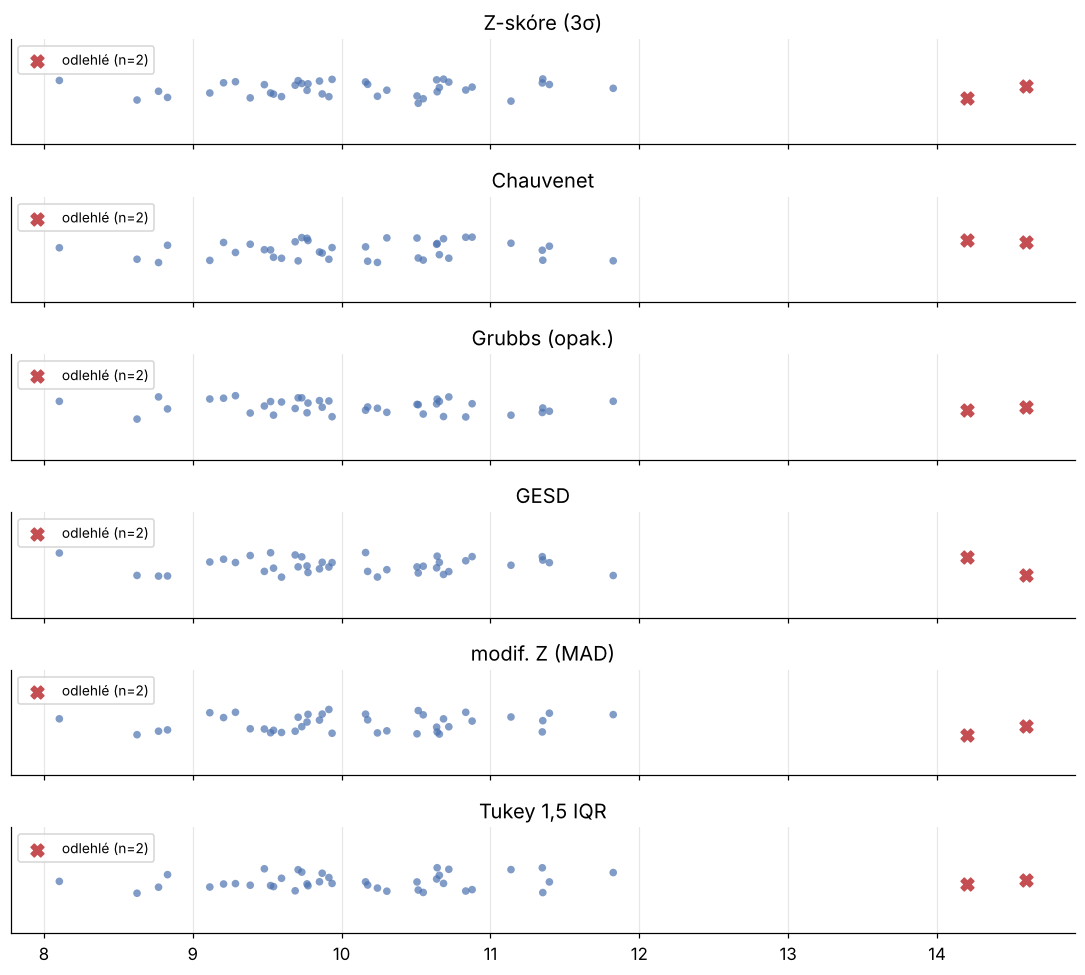

                označeno  správně
Z-skóre (3σ)           2        2
Chauvenet              2        2
Grubbs (opak.)         2        2
GESD                   2        2
modif. Z (MAD)         2        2
Tukey 1,5 IQR          2        2


In [12]:
def all_methods(x):
    return {
        'Z-skóre (3σ)': zscore_rule(x)[0],
        'Chauvenet': chauvenet(x),
        'Grubbs (opak.)': np.isin(np.arange(len(x)), grubbs_iterative(x)),
        'GESD': np.isin(np.arange(len(x)), gesd(x, r=min(10, len(x) // 4))[0]),
        'modif. Z (MAD)': modified_z(x)[0],
        'Tukey 1,5 IQR': tukey(x),
    }

res_sim = all_methods(x_sim)
fig, axes = plt.subplots(len(res_sim), 1, figsize=(10, 9), sharex=True)
for ax, (name, f) in zip(axes, res_sim.items()):
    strip(ax, x_sim, f, name)
plt.tight_layout(); plt.show()

print(pd.DataFrame({m: {'označeno': f.sum(), 'správně': (f & true_out).sum()} for m, f in res_sim.items()}).T)

### Reálná data: Iris – šířka kališního lístku

Pozor: data obsahují **tři druhy** kosatců. Hodnota, která je odlehlá vůči celé datové sadě,
nemusí být odlehlá v rámci svého druhu – a naopak.

In [13]:
res_iris = all_methods(x_iris)
display(pd.DataFrame({m: [', '.join('{:.1f}'.format(v) for v in np.sort(x_iris[f]))]
                      for m, f in res_iris.items()}, index=['označené hodnoty']).T)

# stejna analyza zvlast pro kazdy druh
species = iris.frame['target'].map(dict(enumerate(iris.target_names)))
rows = []
for sp in iris.target_names:
    xs = x_iris[species == sp]
    rows.append({'druh': sp, **{m: ', '.join('{:.1f}'.format(v) for v in np.sort(xs[f])) or '–'
                                for m, f in all_methods(xs).items()}})
display(pd.DataFrame(rows).set_index('druh').T)

,označené hodnoty
Z-skóre (3σ),4.4
Chauvenet,4.4
Grubbs (opak.),
GESD,
modif. Z (MAD),
"Tukey 1,5 IQR","2.0, 4.1, 4.2, 4.4"


druh,setosa,versicolor,virginica
Z-skóre (3σ),–,–,–
Chauvenet,2.3,–,–
Grubbs (opak.),–,–,–
GESD,–,–,–
modif. Z (MAD),–,–,–
"Tukey 1,5 IQR","2.3, 4.4",–,"2.2, 3.8, 3.8"


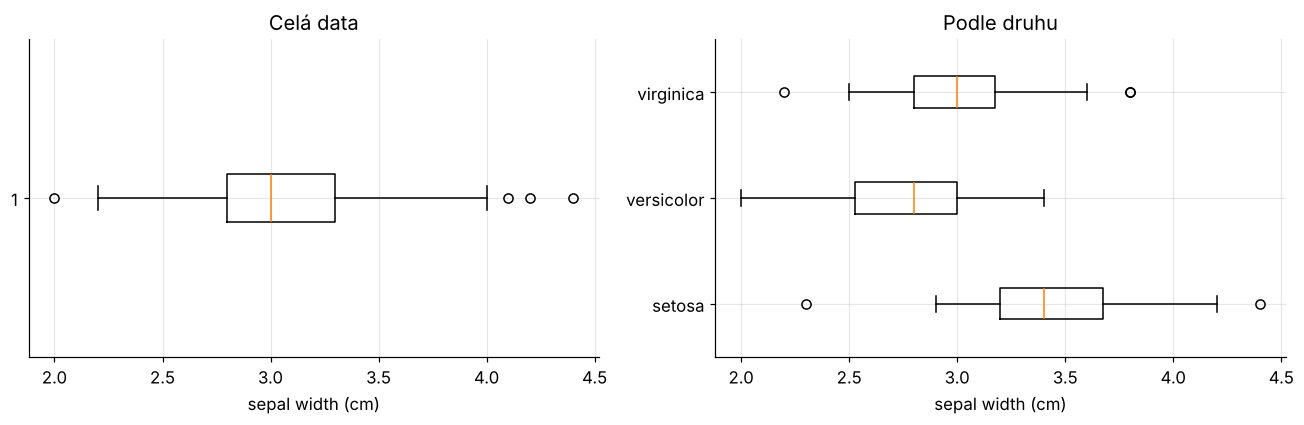

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].boxplot(x_iris, orientation='horizontal')
axes[0].set_title('Celá data')
axes[1].boxplot([x_iris[species == sp] for sp in iris.target_names], orientation='horizontal',
                tick_labels=list(iris.target_names))
axes[1].set_title('Podle druhu')
for ax in axes:
    ax.set_xlabel('sepal width (cm)')
plt.tight_layout(); plt.show()

**Komentář:** na celé datové sadě označí Tukeyho pravidlo čtyři hodnoty, parametrické testy jen hodnotu 4,4
a robustní modifikované Z-skóre žádnou. Rozdělení celé datové sady je směsí tří druhů, takže předpoklad
normality parametrických testů není splněn. Po rozdělení podle druhu se mění i to, které hodnoty jsou
podezřelé (např. 2,3 u druhu setosa) – odlehlost je vždy **relativní vůči zvolenému modelu**.

---
# 6. Robustní odhady polohy

Místo hledání a odstraňování odlehlých hodnot lze použít odhady, na které mají odlehlé hodnoty jen malý vliv:
medián, useknutý průměr (*trimmed mean*), Tukeyho trimean $\frac{Q_1+2Q_2+Q_3}{4}$, winsorizovaný průměr.

Simulací sledujeme, jak se odhady mění s rostoucím podílem kontaminace (část dat z $N(10, 1)$
nahradíme hodnotami z $N(20, 1)$).

,průměr,medián,useknutý průměr 10 %,trimean,winsorizovaný 10 %
kontaminace,,,,,
0.00,10.00,10.00,10.00,10.00,10.00
0.02,10.20,10.03,10.04,10.03,10.04
0.05,10.50,10.07,10.09,10.08,10.11
0.10,11.00,10.13,10.20,10.16,10.29
0.20,11.99,10.31,11.35,10.41,11.96
0.30,13.00,10.57,12.56,12.45,12.98


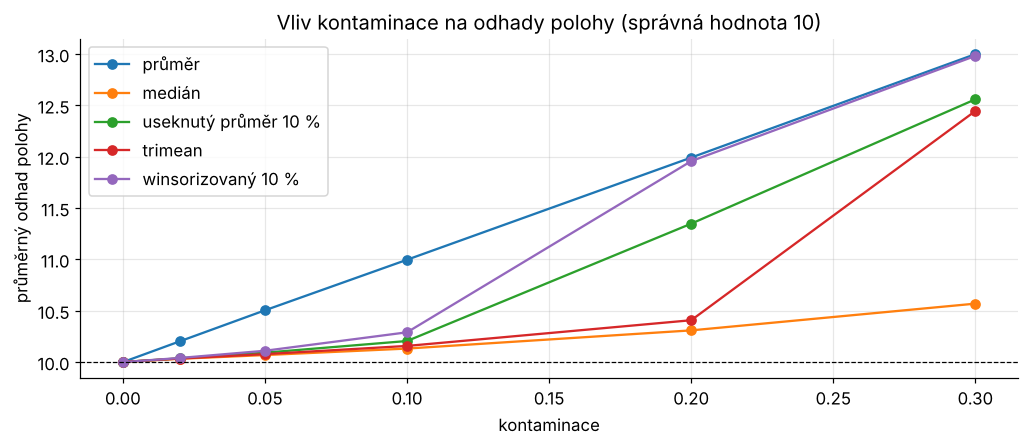

In [15]:
def trimean(x):
    q1, q2, q3 = np.percentile(x, [25, 50, 75])
    return (q1 + 2 * q2 + q3) / 4

estimators = {
    'průměr': np.mean,
    'medián': np.median,
    'useknutý průměr 10 %': lambda x: stats.trim_mean(x, 0.1),
    'trimean': trimean,
    'winsorizovaný 10 %': lambda x: np.mean(stats.mstats.winsorize(x, limits=(0.1, 0.1))),
}

eps_list = [0, 0.02, 0.05, 0.1, 0.2, 0.3]
n, B = 100, 500
rows = []
for eps in eps_list:
    m_out = int(eps * n)
    est = {name: [] for name in estimators}
    for _ in range(B):
        x = np.r_[RNG.normal(10, 1, n - m_out), RNG.normal(20, 1, m_out)]
        for name, f in estimators.items():
            est[name].append(f(x))
    rows.append({'kontaminace': eps, **{name: np.mean(v) for name, v in est.items()}})
tab_rob = pd.DataFrame(rows).set_index('kontaminace')
display(tab_rob.round(2))

tab_rob.plot(marker='o')
plt.axhline(10, color='k', lw=0.8, ls='--')
plt.ylabel('průměrný odhad polohy'); plt.title('Vliv kontaminace na odhady polohy (správná hodnota 10)')
plt.show()

Průměr má **bod zvratu** (breakdown point) $1/n$ – jediná hodnota jej může libovolně posunout.
Useknutý průměr s 10 % na každé straně vydrží do 10 % kontaminace, medián až do 50 %.

---
# 7. Co s odlehlými hodnotami dělat

1. **Ověřit**, zda nejde o chybu (záznam, jednotky, měření). Chybu opravit, nebo hodnotu vyřadit.
2. Pokud jde o skutečnou hodnotu, **neodstraňovat automaticky** – může nést nejzajímavější informaci.
3. Použít **robustní metody** (medián, MAD, robustní regrese), případně analýzu provést s odlehlými hodnotami i bez nich a porovnat.
4. Nahradit (MATLAB `filloutliers`): ořezání na hranici (*clip*, winsorizace), nahrazení mediánem, interpolace (u časových řad).

In [16]:
f = tukey(x_sim)
q1, q3 = np.percentile(x_sim, [25, 75])
lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)

x_clip = np.clip(x_sim, lo, hi)                       # orezani na hradby (clip)
x_med = np.where(f, np.median(x_sim), x_sim)          # nahrazeni medianem
x_del = x_sim[~f]                                     # vyrazeni

print(pd.DataFrame({
    'původní': [x_sim.mean(), x_sim.std(ddof=1)],
    'clip': [x_clip.mean(), x_clip.std(ddof=1)],
    'medián': [x_med.mean(), x_med.std(ddof=1)],
    'vyřazení': [x_del.mean(), x_del.std(ddof=1)],
}, index=['průměr', 's']).round(3))

        původní    clip  medián  vyřazení
průměr   10.264  10.166  10.056    10.057
s         1.237   0.948   0.808     0.828


---
# 8. Úlohy

1. Simulací ověřte, že Grubbsův test dodržuje hladinu $\alpha=0{,}05$ pro $n=10$ a $n=100$ (podíl zamítnutí na čistě normálních datech).
2. Stejnou simulací zjistěte, jaká je skutečná hladina **opakovaného** Grubbsova testu, pokud jej provedeme nejvýše třikrát.
3. Porovnejte, kolik hodnot označí Tukeyho pravidlo na výběru rozsahu 1000 z exponenciálního rozdělení. Proč jich je tolik? Jak by vypadalo pravidlo pro zešikmená data (např. po logaritmické transformaci)?
4. Pro data `x_mask` najděte nejmenší vzdálenost dvou odlehlých hodnot od hlavní skupiny, při které je opakovaný Grubbsův test začne odhalovat.